<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Imports
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [159]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np
from itertools import product
import seaborn as sns


In [33]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

In [7]:
from helper_functions import find_gaps, plot_forecast, plot_subseries, is_in_gap

<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Hyperparameter Search
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style="font-weight: bold;"> Cross Validation Process: </span>

The process for cross validation and grid search was done similarly to the one described on the official git of the Prophet Model https://github.com/facebook/prophet/blob/main/notebooks/diagnostics.ipynb. The parameters for the cross validation (initial, period and horizon) were inspired by this description but scaled down to the smaller dataset and adjusted for a stronger impact of the trend. That is, the model should only predict 30 days ahead, as the trend picks up significantly towards the end. The initial must be at least 365.25 days because we include yearly seasonality into the model. For these reasons we end up with 9 total forecasts -instead of 11 like described in the process on github- for each hyperparameter combination.


<span style="font-weight: bold;"> Cross Validation Parameters: </span>
The following parameters were trained in the hyperparameter search with cross validation. These are the parameters with the most impact on model performance. Due to computational limitations , we were limited to a rather small parameter grid, as 24 parameter combinations already takes more than 90 minutes. The parameters provided to the grid search were learned trough trial and error and previous grid searchs with different parameters and in reference to the github linked above.
<ul>
    <li><strong>Seasonality Prior Scale </strong> 
    <li><strong>Changepoint Range </strong> 
    <li><strong>Changepoint Prior Scale</strong>
    <li><strong>Holidays Prior Scale</strong> 



<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        1. Data Preparation
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [16]:
# === Step 1: Prepare data ===
..\data\utilization_final.csv
data = pd.read_csv('..\data\utilization_final.csv')
#data = data[data.site_01==0]

# make the binary features numeric
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)
# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

data_for_cv = data[data['timestamp'] >= '2018-10-08'].copy()
data_gaps = find_gaps(data_for_cv )
data_for_cv .rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


# we know that the time ranges for the 2 sites are :
# Site 1 Timespan: 2018-09-05 04:04:13 - 2021-09-14 07:46:28
# Site 2 Timespan: 2018-04-25 04:08:04 - 2021-09-13 20:05:10
# we must consider that when selecting the training data, so that we do not introduce any biases 
train_data = data_for_cv [(data_for_cv ['ds'] < '2021-08-16') & (data_for_cv ['ds'] >= '2018--10--08 06:00')]


<span style="font-weight: bold;"> Holidays: </span>

We manually specify holidays for California, as they differ slightly from the built-in holidays in the Prophet Model, which are for the entire USA and not specific to California. The information about the holidays was sourced <a href="https://leaveboard.com/public-holidays/united-states-california-public-holidays-2018/" target="_blank">from this website</a>.


In [8]:

holidays_str = [
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
    '2022-01-01','2022-01-17', '2022-02-21','2022-03-31','2022-05-30','2022-07-04',
    '2022-09-05','2022-11-11','2022-11-24','2022-11-25', '2022-12-26'
]



holidays = pd.DataFrame({
      'holiday': ['Holiday'] * len(holidays_str),  
    'ds': pd.to_datetime(holidays_str),
  'lower_window': 0,
  'upper_window': 0,
})




<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        2. Hyperparameter Search with Cross Validation
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [18]:
# Define parameter grid 
param_grid = {
    'seasonality_prior_scale': [25, 50],
    'changepoint_range': [ 0.99, 0.95],
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'holidays_prior_scale': [ 1, 5]
}

# Generate all combinations of parameters
all_params = [dict(zip(param_grid.keys(), v)) for v in product(*param_grid.values())]

# Storage for results
results = []



for params in all_params:
        model = Prophet(
            yearly_seasonality='auto',
            weekly_seasonality='auto',
            daily_seasonality=False,
            seasonality_mode="multiplicative",
            holidays_prior_scale=params['holidays_prior_scale'],
            changepoint_prior_scale=params['changepoint_prior_scale'],
            seasonality_prior_scale=params['seasonality_prior_scale'],
            changepoint_range=params['changepoint_range']
        )
        
        # Add conditional seasonalities and regressors
        
        model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
        model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
        model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
        model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)
        model.add_regressor('post_covid', mode='additive', prior_scale=0.05)
        
        # Fit model
        model.fit(train_data)
        
        # Cross validation
        cv_results = cross_validation(
            model,
            initial='365.25 days',
            period='90 days',
            horizon='30 days',
            parallel="processes"
        )
        
        # Performance metrics
        metrics = performance_metrics(cv_results)
        
        # Store results 
        results.append({
            'params': params,
            'mae': metrics['mae'].mean(),
        })
       
        print(f"Completed parameters: {params}")
        print(f" MAE: {metrics['mae'].mean():.4f}")
        print("-" * 50)


# Convert results to dataframe
results_df = pd.DataFrame(results)

# Find best hyperparameters and print them
best_params = results_df.loc[results_df['mae'].idxmin(), 'params']
print("\
Best parameters:")
print(f"Seasonality Prior Scale: {best_params['seasonality_prior_scale']}")
print(f"Changepoint Range: {best_params['changepoint_range']}")
print(f"Changepoint Prior Scale: {best_params['changepoint_prior_scale']}")
print(f"Holidays Prior Scale: {best_params['holidays_prior_scale']}")
print("\
Best metrics:")
print(results_df.loc[results_df['mae'].idxmin(), [ 'mae']])

17:15:08 - cmdstanpy - INFO - Chain [1] start processing
17:15:43 - cmdstanpy - INFO - Chain [1] done processing
17:15:55 - cmdstanpy - INFO - Chain [1] start processing
17:15:57 - cmdstanpy - INFO - Chain [1] start processing
17:15:59 - cmdstanpy - INFO - Chain [1] start processing
17:16:01 - cmdstanpy - INFO - Chain [1] start processing
17:16:03 - cmdstanpy - INFO - Chain [1] start processing
17:16:05 - cmdstanpy - INFO - Chain [1] done processing
17:16:05 - cmdstanpy - INFO - Chain [1] start processing
17:16:07 - cmdstanpy - INFO - Chain [1] start processing
17:16:08 - cmdstanpy - INFO - Chain [1] start processing
17:16:12 - cmdstanpy - INFO - Chain [1] done processing
17:16:13 - cmdstanpy - INFO - Chain [1] done processing
17:16:29 - cmdstanpy - INFO - Chain [1] done processing
17:16:37 - cmdstanpy - INFO - Chain [1] done processing
17:16:48 - cmdstanpy - INFO - Chain [1] done processing
17:16:51 - cmdstanpy - INFO - Chain [1] done processing
17:17:01 - cmdstanpy - INFO - Chain [1]

Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 1}
 MAE: 0.0802
--------------------------------------------------


17:17:14 - cmdstanpy - INFO - Chain [1] start processing
17:17:49 - cmdstanpy - INFO - Chain [1] done processing
17:18:00 - cmdstanpy - INFO - Chain [1] start processing
17:18:02 - cmdstanpy - INFO - Chain [1] start processing
17:18:03 - cmdstanpy - INFO - Chain [1] start processing
17:18:05 - cmdstanpy - INFO - Chain [1] start processing
17:18:07 - cmdstanpy - INFO - Chain [1] start processing
17:18:08 - cmdstanpy - INFO - Chain [1] done processing
17:18:09 - cmdstanpy - INFO - Chain [1] start processing
17:18:10 - cmdstanpy - INFO - Chain [1] start processing
17:18:12 - cmdstanpy - INFO - Chain [1] start processing
17:18:15 - cmdstanpy - INFO - Chain [1] done processing
17:18:16 - cmdstanpy - INFO - Chain [1] done processing
17:18:32 - cmdstanpy - INFO - Chain [1] done processing
17:18:40 - cmdstanpy - INFO - Chain [1] done processing
17:18:51 - cmdstanpy - INFO - Chain [1] done processing
17:18:53 - cmdstanpy - INFO - Chain [1] done processing
17:19:04 - cmdstanpy - INFO - Chain [1]

Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 5}
 MAE: 0.0802
--------------------------------------------------


17:19:17 - cmdstanpy - INFO - Chain [1] start processing
17:20:14 - cmdstanpy - INFO - Chain [1] done processing
17:20:25 - cmdstanpy - INFO - Chain [1] start processing
17:20:26 - cmdstanpy - INFO - Chain [1] start processing
17:20:28 - cmdstanpy - INFO - Chain [1] start processing
17:20:30 - cmdstanpy - INFO - Chain [1] start processing
17:20:32 - cmdstanpy - INFO - Chain [1] start processing
17:20:34 - cmdstanpy - INFO - Chain [1] start processing
17:20:36 - cmdstanpy - INFO - Chain [1] start processing
17:20:37 - cmdstanpy - INFO - Chain [1] start processing
17:20:39 - cmdstanpy - INFO - Chain [1] done processing
17:20:43 - cmdstanpy - INFO - Chain [1] done processing
17:21:15 - cmdstanpy - INFO - Chain [1] done processing
17:21:42 - cmdstanpy - INFO - Chain [1] done processing
17:21:53 - cmdstanpy - INFO - Chain [1] done processing
17:21:54 - cmdstanpy - INFO - Chain [1] done processing
17:22:13 - cmdstanpy - INFO - Chain [1] done processing
17:22:13 - cmdstanpy - INFO - Chain [1]

Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.05, 'holidays_prior_scale': 1}
 MAE: 0.0720
--------------------------------------------------


... (38 outputs left out)

18:34:12 - cmdstanpy - INFO - Chain [1] start processing
18:35:00 - cmdstanpy - INFO - Chain [1] done processing
18:35:10 - cmdstanpy - INFO - Chain [1] start processing
18:35:11 - cmdstanpy - INFO - Chain [1] start processing
18:35:13 - cmdstanpy - INFO - Chain [1] start processing
18:35:14 - cmdstanpy - INFO - Chain [1] start processing
18:35:16 - cmdstanpy - INFO - Chain [1] start processing
18:35:18 - cmdstanpy - INFO - Chain [1] start processing
18:35:19 - cmdstanpy - INFO - Chain [1] start processing
18:35:21 - cmdstanpy - INFO - Chain [1] start processing
18:35:25 - cmdstanpy - INFO - Chain [1] done processing
18:35:54 - cmdstanpy - INFO - Chain [1] done processing
18:36:26 - cmdstanpy - INFO - Chain [1] done processing
18:36:29 - cmdstanpy - INFO - Chain [1] done processing
18:37:08 - cmdstanpy - INFO - Chain [1] done processing
18:37:13 - cmdstanpy - INFO - Chain [1] done processing
18:37:15 - cmdstanpy - INFO - Chain [1] done processing
18:37:17 - cmdstanpy - INFO - Chain [1]

Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 1}
 MAE: 0.0701
--------------------------------------------------


18:37:27 - cmdstanpy - INFO - Chain [1] start processing
18:38:14 - cmdstanpy - INFO - Chain [1] done processing
18:38:24 - cmdstanpy - INFO - Chain [1] start processing
18:38:25 - cmdstanpy - INFO - Chain [1] start processing
18:38:27 - cmdstanpy - INFO - Chain [1] start processing
18:38:29 - cmdstanpy - INFO - Chain [1] start processing
18:38:30 - cmdstanpy - INFO - Chain [1] start processing
18:38:31 - cmdstanpy - INFO - Chain [1] start processing
18:38:33 - cmdstanpy - INFO - Chain [1] start processing
18:38:34 - cmdstanpy - INFO - Chain [1] start processing
18:38:37 - cmdstanpy - INFO - Chain [1] done processing
18:39:05 - cmdstanpy - INFO - Chain [1] done processing
18:39:40 - cmdstanpy - INFO - Chain [1] done processing
18:39:43 - cmdstanpy - INFO - Chain [1] done processing
18:40:19 - cmdstanpy - INFO - Chain [1] done processing
18:40:25 - cmdstanpy - INFO - Chain [1] done processing
18:40:27 - cmdstanpy - INFO - Chain [1] done processing
18:40:29 - cmdstanpy - INFO - Chain [1]

Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 5}
 MAE: 0.0701
--------------------------------------------------
Best parameters:
Seasonality Prior Scale: 50
Changepoint Range: 0.95
Changepoint Prior Scale: 0.1
Holidays Prior Scale: 1
Best metrics:
mae    0.070053
Name: 22, dtype: object


<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Fit and Forecast
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        1. Data Preparation
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

<div class="alert alert-block alert-warning">
<b>Disclaimer:</b> Please note that we do not scale the data, like we do for the neural network. This is because Prophet automatically scales the data. There are two moduses 1. minmax scaling 2. absmax scaling. As they both yielded the same test and training error, we opted to go for the default parameter (in the init of the model). Individually scaling also does not make sense in this case.
</div>

In [224]:
# === Step 1: Prepare data ===

# load in a new instance 
data = pd.read_csv('..\data\utilization_final.csv')

# make the binary features numeric for the model
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)

# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

# let us create a copy to avoid errors
data_final = data.copy()

# use the imported functions to find the data gaps in the data frame
data_gaps = find_gaps(data_final)

# prepare the variable names for the Prophet model
data_final.rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        2. Create a test-train-split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

From our data preparation notebook, we know that the time ranges for the 2 sites are :
    <li><strong>Site 1 Timespan:</strong> 2018-09-05 04:04:13 - 2021-09-14 07:46:28
    <li><strong>Site 2 Timespan:</strong> 2018-04-25 04:08:04 - 2021-09-13 20:05:10
    
We must consider that when setting the test and train split, so that we do not introduce any biases.
We use a test dataset of 4 consecutive weeks, FIND PRECEDENCE HERE FOR SURE. A larger testset is problematic, because the trend picks up significantly towards the last months.

We use 4 weeks of consecutive data for the test split. XXXXXXXXXXX

In [225]:
train_data = data_final[(data_final['ds'] < '2021-08-16') & (data_final['ds'] >= '2018-10-08 06:00')]
test_data = data_final[(data_final['ds'] >= '2021-08-16') &(data_final['ds']<= '2021-09-13 19:00')]

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        3. Initialize the Prophet model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

We tested the model without custom seasonalities and custom seasonalities with different fourier orders through trial and error. As the hyperparameter search already takes several hours, we did not add the additional parameters in the hyperparameter search in this notebook. But there were a couple things that held true in the experimentation of said parameters/options:
    <li><strong>More flexible seasonalities:</strong> Higher fourier orders i.e. more flexible seasonalities generally have lower test errors
    <li><strong>Custom seasonalities:</strong> Adding custom weekly and daily seasonalities for the two sites improves the test error
We also add regressors to the model, that were also included in the neural network:
    <li><strong>In gap:</strong> Indicating whether or not the timestamp is in a data gap. Is added to the trend
    <li><strong>Post covid:</strong> Indicating whether or not the timestamp was after the COVID dropoff. Is added to the trend
    <li><strong>Site 1:</strong> Indicating whether or not the session belongs to site 1. Multiplies the trend, as site 1 has a stronger trend
It was also tested whether additive or multiplicative trend worked better for each regressor. Again, due to lack of computational power, this can not be showcased in the grid search.
    <li><strong>Weather:</strong> None of the weather data noticeably improve the model performance. The inclusion, however, increases the runtime of the model, which is problematic for the grid search. For this reason we opted to exclude the weather features. The inclusion is very easily done, though. Just remove the # of the line in the model initialization and add the features to the array in the 'model.predict' lines of code.

<h2>Parameters from grid search</h2>
These were the optimal hyperparameters determined with grid search and cross validation.
<ul>
    <li><strong>Seasonality Prior Scale: </strong> 50
    <li><strong>Changepoint Range: </strong> 0.95
    <li><strong>Changepoint Prior Scale:</strong> 0.1
    <li><strong>Holidays Prior Scale:</strong> 1


In [226]:
model = Prophet(
    yearly_seasonality='auto',
    weekly_seasonality=False,
    daily_seasonality=False,
    holidays=holidays,
    seasonality_mode="multiplicative",
    holidays_prior_scale=1,
    changepoint_prior_scale=0.1,
    seasonality_prior_scale=50,
    changepoint_range=0.95   
)

# lets add custom seasonalities for site 1
model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
model.add_seasonality(name='weekly_site1', period=7, fourier_order=9, condition_name='site_01_bool')

# lets add custom seasonalities for site 2
model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
model.add_seasonality(name='weekly_site2', period=7, fourier_order=9, condition_name='site_02')


# add additive regressors

model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
model.add_regressor('post_covid', mode='additive', prior_scale=0.05)

# add multiplicative regressors
model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)


# yearly custom seasonality does not improve the model, but increases runtime:
#model.add_seasonality(name='yearly_site1', period=365.25, fourier_order=15, condition_name='site_01_bool')
#model.add_seasonality(name='yearly_site2', period=365.25, fourier_order=15, condition_name='site_02')

# add the weather data 
#model.add_regressor('precipitation', mode='additive', prior_scale=0.05)
#model.add_regressor('temperature', mode='additive', prior_scale=0.05)

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        4. Fit the model on the training data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [227]:
# fit the model
model.fit(train_data)



19:55:35 - cmdstanpy - INFO - Chain [1] start processing
19:56:40 - cmdstanpy - INFO - Chain [1] done processing


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        5. Predict on the test data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [228]:

# Create copies of test and train data to avoid errors
test = test_data.copy()  
train = train_data.copy()  

# ensure the ds column has the correct data type
test['ds'] = pd.to_datetime(test['ds'])
train['ds'] = pd.to_datetime(train['ds'])


# make the forecast
# add 'precipitation' and 'temperature' to the feature array if you want to add weather features
forecast_test = model.predict(test[['ds', 'in_gap', 'site_01','site_01_bool', 'site_02', 'post_covid']])

# merge forecast and original dataframe 
# add 'precipitation' and 'temperature' to the feature array if you want to add weather features
test_merged = test.merge(forecast_test[['ds', 'yhat']], on='ds', how='left')

train_forecast = model.predict(train_data[['ds', 'in_gap', 'site_01', 'site_01_bool', 'site_02', 'post_covid']])
train_merged = train.merge(train_forecast[['ds', 'yhat']], on='ds', how='left')


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        6. Evaluate the model performance
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [229]:
# Compute performance metrics for test and training data

metrics = {
    'Dataset': ['Training', 'Test'],
    'MAE': [
        mean_absolute_error(train_merged['y'], train_merged['yhat']),
        mean_absolute_error(test_merged['y'], test_merged['yhat'])
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(train_merged['y'], train_merged['yhat'])),
        np.sqrt(mean_squared_error(test_merged['y'], test_merged['yhat']))
    ]
}

metrics_df = pd.DataFrame(metrics)
print(metrics_df)

    Dataset       MAE      RMSE
0  Training  0.088049  0.165402
1      Test  0.081121  0.140813


<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Visualizations
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        1. Filter the data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [248]:
# concat test and train data (as they have all the data in the right format)
actual_utilizations = pd.concat([train_data, test_data], axis=0, ignore_index=True)
# concat the predictions for the training and test data
concated = pd.concat([train_forecast, forecast_test], axis=0, ignore_index=True)

# filter the dataframes for the sites

# ----------------- Site 01 -------------------------------
site1_actual = actual_utilizations[actual_utilizations.site_01==1]
site1_forecast = concated[concated.site_01>0]
site1_test_forecast = forecast_test[forecast_test.site_01>0]
site1_test_actual = test_data[test_data.site_01==1]

# ----------------- Site 02 -------------------------------

site2_actual = actual_utilizations[actual_utilizations.site_01==0]
site2_forecast = concated[concated.site_01==0]
site2_test_forecast = forecast_test[forecast_test.site_01==0]
site2_test_actual = test_data[test_data.site_01==0]


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        2. Visualize the forecasts for site 1
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

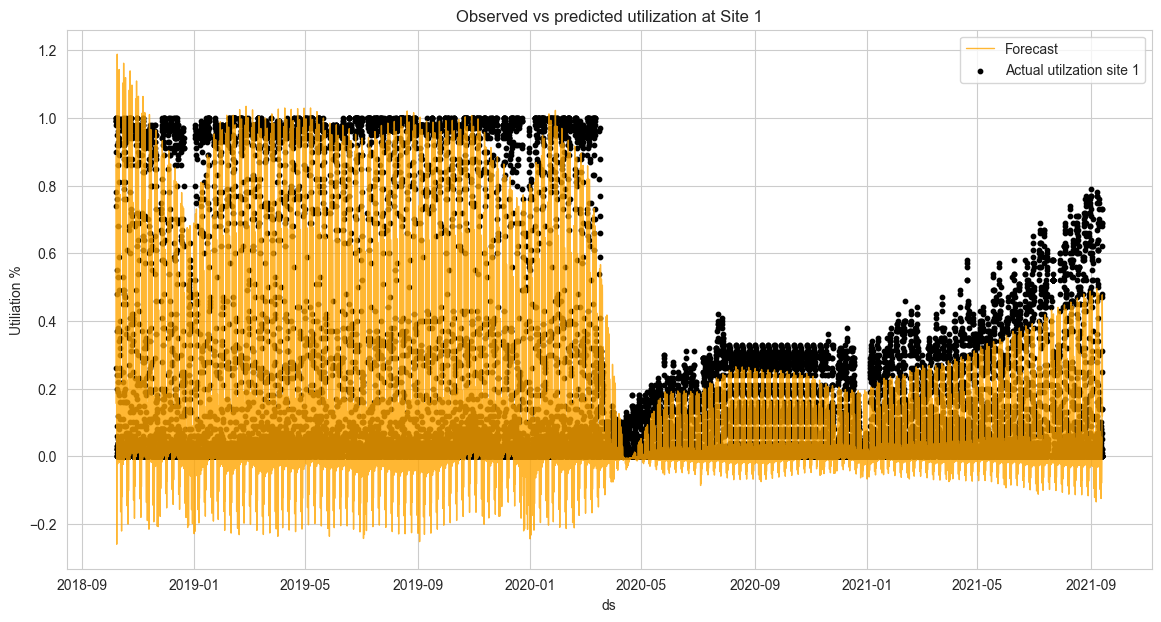

In [231]:

plt.figure(figsize=(14, 7))
# Plot forecasted utilization
plt.plot(site1_forecast["ds"], site1_forecast["yhat"], color="orange", label="Forecast", linewidth=1, alpha=0.8)

# Plot actual utilization
plt.scatter(site1_forecast["ds"], site1_actual["y"], color="black", s=10, label="Actual utilzation site 1")



# Labels and legend
plt.xlabel("ds")
plt.ylabel("Utiliation %")
plt.title('Observed vs predicted utilization at Site 1')
plt.legend()
plt.show()

<span style="font-weight: bold;"> Analysis: </span>
We can observe that the model systematically underestimates utilizations for site 1 after the structural break. This is because it can only fit a single trend line for both sites and after the pandemic site 1 showcased a  much faster recoverery than site 2. 

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        3. Visualize the forecasts for site 2
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

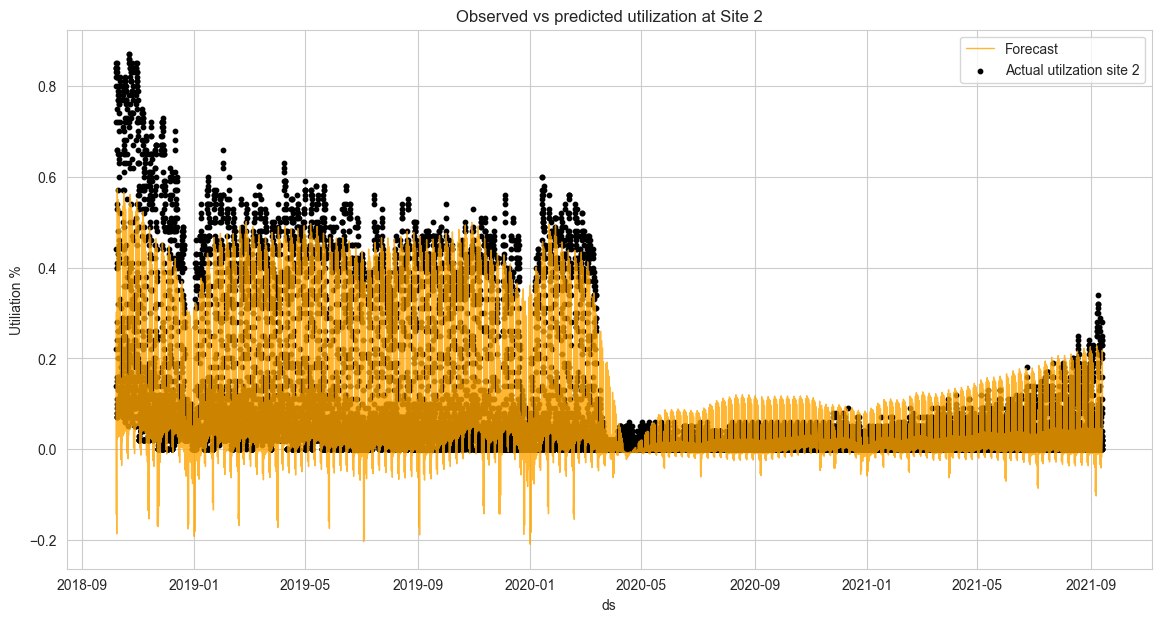

In [232]:

plt.figure(figsize=(14, 7))
# Plot forecasted utilization
plt.plot(site2_forecast["ds"], site2_forecast["yhat"], color="orange", label="Forecast", linewidth=1, alpha=0.8)

# Plot actual utilization
plt.scatter(site2_forecast["ds"], site2_actual["y"], color="black", s=10, label="Actual utilzation site 2")



# Labels and legend
plt.xlabel("ds")
plt.ylabel("Utiliation %")
plt.title('Observed vs predicted utilization at Site 2')
plt.legend()
plt.show()

<span style="font-weight: bold;"> Analysis: </span>
We can see  the exact  opposite to the previous plot. For site 2, the model tends to overestimate utilizations during the peaks. One trend line cannot be fit accurately to two sites with vastly different trend curves.

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        4. Visualize the forecasts for site 1 for the test split

</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

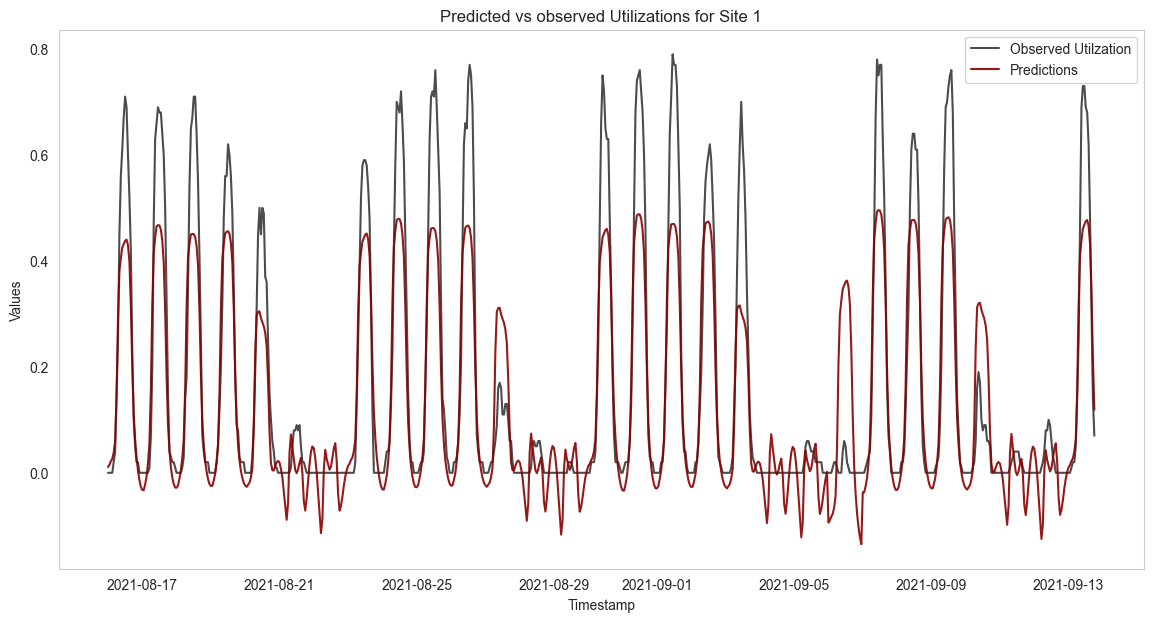

In [247]:
# Plot the Predictions
plt.figure(figsize=(14, 7))

plt.plot(site1_test_forecast['ds'], site1_test_actual['y'], label='Observed Utilzation', color='black', alpha=0.7)
plt.plot(site1_test_forecast['ds'], site1_test_forecast['yhat'], label='Predictions', color='darkred', alpha=0.9)

plt.title('Predicted vs observed Utilizations for Site 1')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

<span style="font-weight: bold;"> Analysis: </span>
Again, we see that the model systematically underestimates utilizations, even resulting in negative values when actual utilizations is close to 0.

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        5. Visualize the forecasts for site 2 for the test split

</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

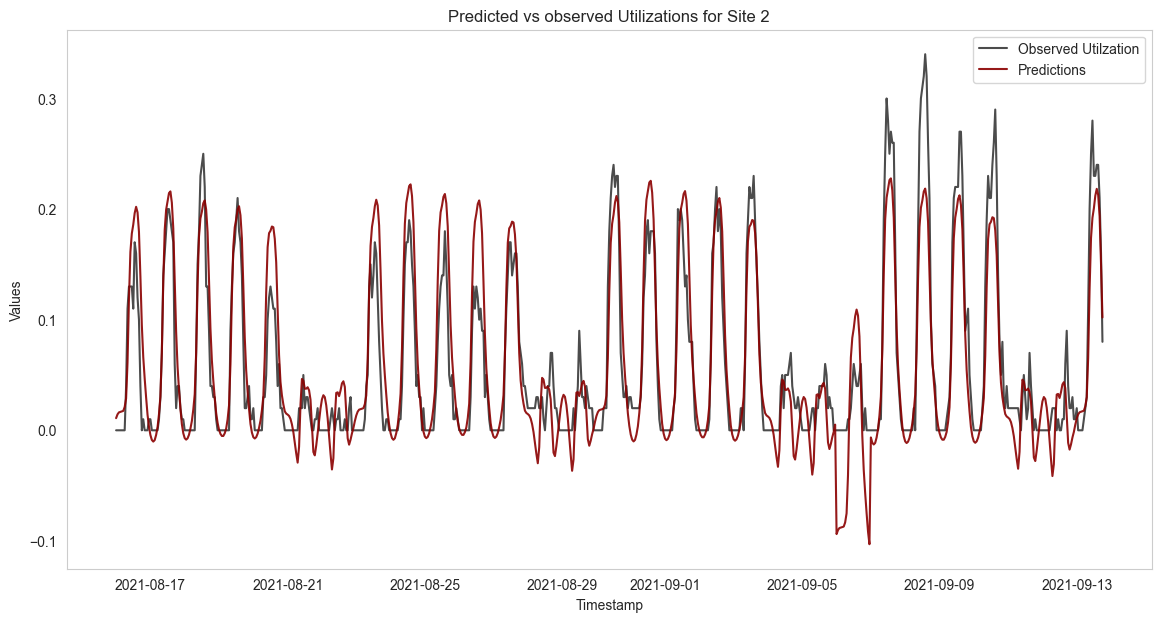

In [249]:
# Plot the Predictions
plt.figure(figsize=(14, 7))

plt.plot(site2_test_forecast['ds'], site2_test_actual['y'], label='Observed Utilzation', color='black', alpha=0.7)
plt.plot(site2_test_forecast['ds'], site2_test_forecast['yhat'], label='Predictions', color='darkred', alpha=0.9)

plt.title('Predicted vs observed Utilizations for Site 2')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

<span style="font-weight: bold;"> Analysis: </span>
We can see that the model does a much better job at predicting the utilization for site 2 in the training data. 

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        6. Visualize the components of the model

</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

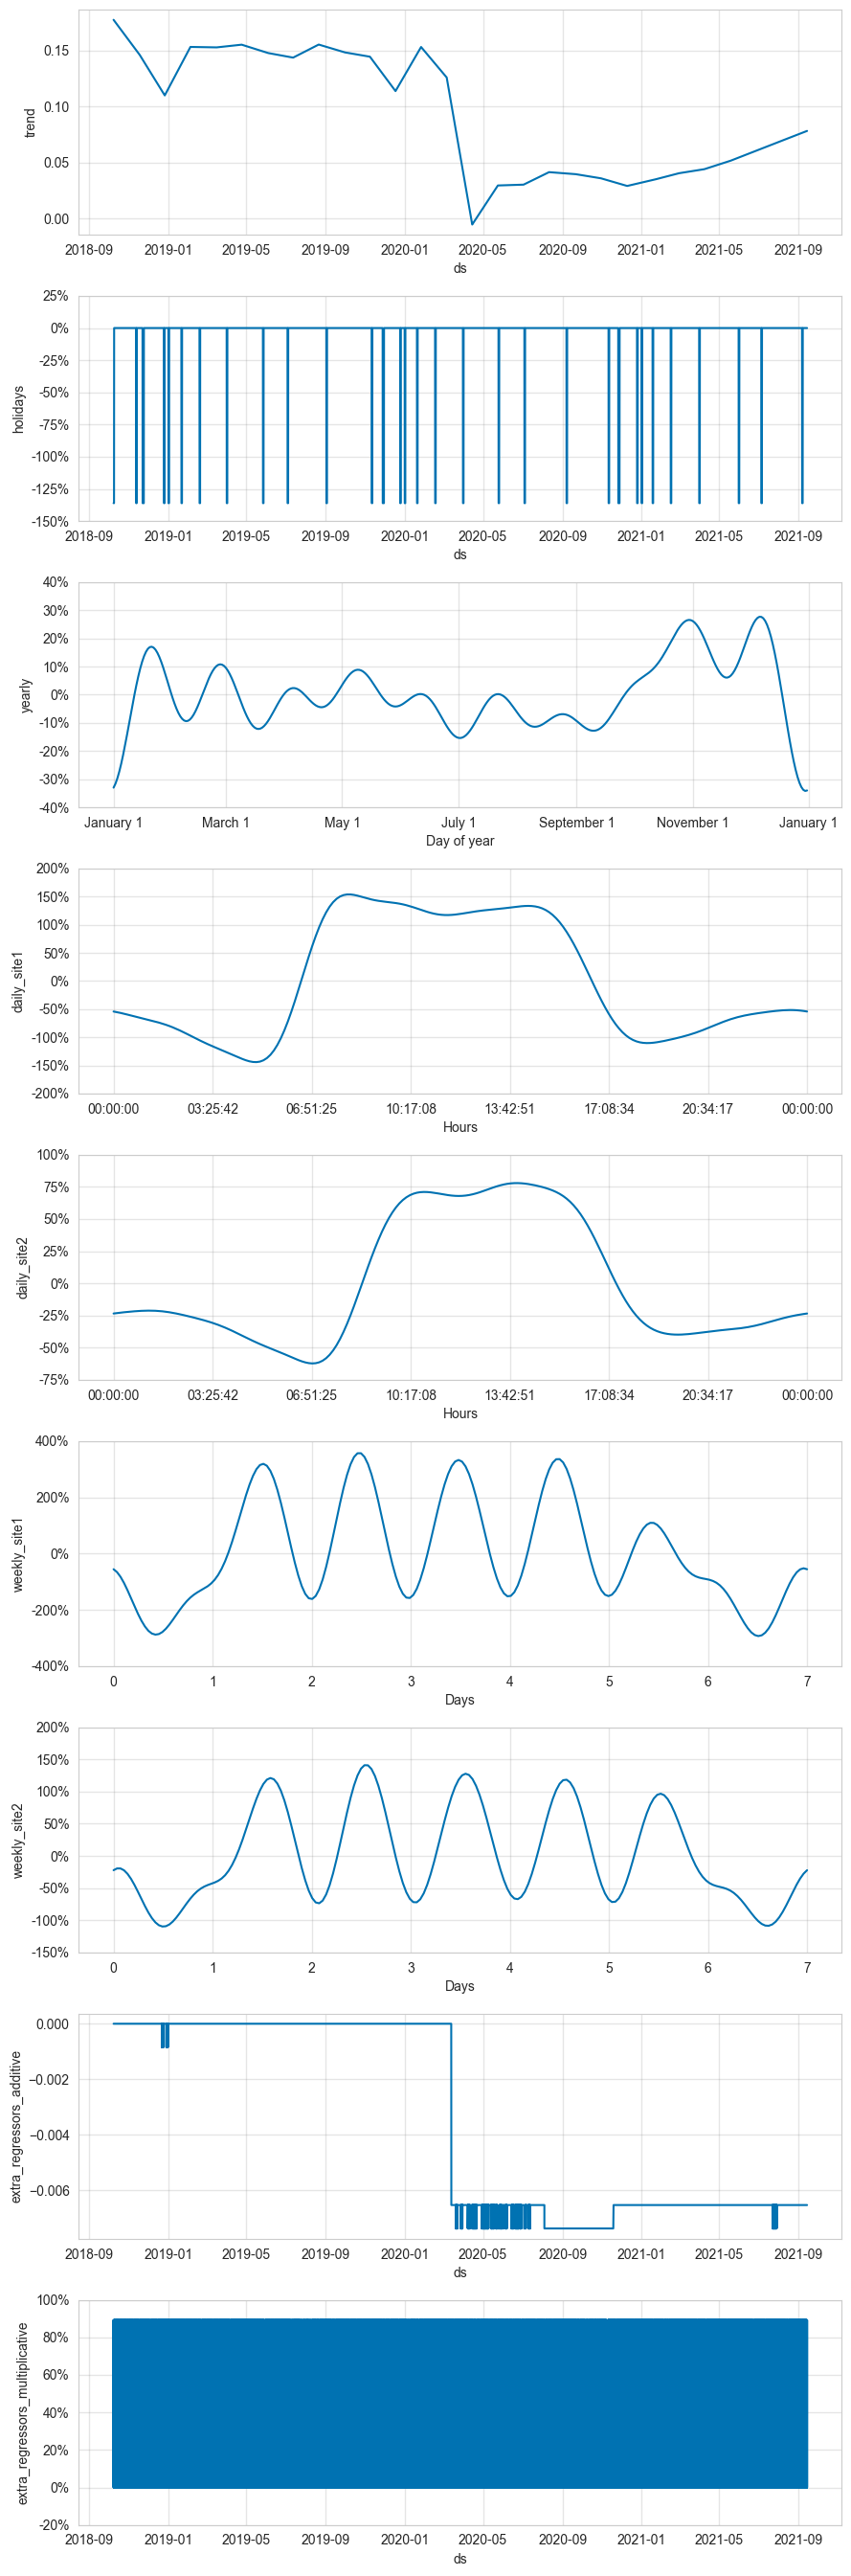

In [235]:
model.plot_components(concated, uncertainty=False)
plt.show()

<span style="font-weight: bold;"> Analysis: </span>
We can see that there are strong daily and weekly cycles at both sites, but they are not the same. Site 2's daily cycle starts several hours later and its weekly cycle leads to higher utilizations on fridays compared to site 1. The components show that it is neccessary to fit site specific seasonalities to catch these nuances. MOreoever, in the additive regressors component, we can see the strong dropoff caused by the pandemic and additional drops caused by the gaps we filled. The holidays lead to significant drops in utilizations, whereas the multiplicative site 1 regressor increases the trend for site 1.